# Cats vs Dogs: Soft Neural Decision Tree

In Colab, select **Runtime > Change runtime type > T4 GPU** (or another GPU) before running. This notebook preserves the CNN feature extractor, independent routing MLPs, leaf MLPs, and soft path weighting of the supplied model.

In [1]:
# Colab already includes PyTorch. This checks the runtime and installs Kaggle only if needed.
import importlib.util, subprocess, sys
if importlib.util.find_spec('kaggle') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kaggle'])
import torch
print('PyTorch:', torch.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'not available — training will use CPU')

PyTorch: 2.11.0+cu130
GPU: Tesla T4


## Get the dataset

**Recommended — Kaggle API:** run the next cell and enter your Kaggle username and API key when prompted. The key is hidden while typing and is saved only in the temporary Colab runtime. If you have `kaggle.json`, uploading it is also supported. The cell downloads `tongpython/cat-and-dog`. If you already uploaded a dataset zip to Colab, skip it and run the alternative cell.

In [2]:
# Kaggle download option (run once). Enter your username and API key; it is not printed.
from pathlib import Path
from getpass import getpass
import json, os, zipfile
kaggle_username = input('Kaggle username: ').strip()
kaggle_key = getpass('Kaggle API key: ').strip()
if not kaggle_username or not kaggle_key: raise RuntimeError('Both username and API key are required.')
Path('/root/.kaggle').mkdir(exist_ok=True)
with open('/root/.kaggle/kaggle.json', 'w') as token_file:
    json.dump({'username': kaggle_username, 'key': kaggle_key}, token_file)
os.chmod('/root/.kaggle/kaggle.json', 0o600)
Path('/content/data').mkdir(exist_ok=True)
subprocess.check_call(['kaggle', 'datasets', 'download', '-d', 'tongpython/cat-and-dog', '-p', '/content/data'])
with zipfile.ZipFile('/content/data/cat-and-dog.zip') as archive:
    archive.extractall('/content/data')
print('Extracted:', [p.name for p in Path('/content/data').iterdir()])

Kaggle username: aydeeead
Kaggle API key: ··········
Extracted: ['cat-and-dog.zip', 'test_set', 'training_set']


In [3]:
# Alternative: upload an already-downloaded zip, then extract it.
# Run this INSTEAD of the Kaggle cell above.
# from google.colab import files
# from pathlib import Path
# import zipfile
# uploaded = files.upload()
# zip_name = next((name for name in uploaded if name.lower().endswith('.zip')), None)
# if zip_name is None: raise RuntimeError('Upload a .zip file.')
# Path('/content/data').mkdir(exist_ok=True)
# with zipfile.ZipFile(zip_name) as archive: archive.extractall('/content/data')

In [4]:
import random
from pathlib import Path
from typing import List, Sequence, Tuple
from PIL import Image, ImageFile
from torch import Tensor, nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
ImageFile.LOAD_TRUNCATED_IMAGES = True
IMAGE_SUFFIXES, CLASS_NAMES = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}, ('cat', 'dog')

def find_labeled_images(data_dir: Path) -> List[Tuple[Path, int]]:
    samples = []
    for image_path in data_dir.rglob('*'):
        if not image_path.is_file() or image_path.suffix.lower() not in IMAGE_SUFFIXES: continue
        parts, name = [p.lower() for p in image_path.parts], image_path.stem.lower()
        if any(p in {'cat', 'cats'} for p in parts[:-1]) or name.startswith(('cat.', 'cat_')): samples.append((image_path, 0))
        elif any(p in {'dog', 'dogs'} for p in parts[:-1]) or name.startswith(('dog.', 'dog_')): samples.append((image_path, 1))
    if any(not any(label == i for _, label in samples) for i in range(2)):
        raise RuntimeError('Could not find both cats and dogs below ' + str(data_dir))
    return samples

def detect_dataset_root(extract_root: Path) -> Path:
    # Prefer known training folders over a broad root that may also contain a test split.
    candidates = [extract_root / 'PetImages', extract_root / 'train', extract_root / 'training_set' / 'training_set', extract_root / 'training_set', extract_root]
    for candidate in candidates:
        if candidate.exists():
            try:
                find_labeled_images(candidate); return candidate
            except RuntimeError: pass
    raise RuntimeError('No supported Cats vs Dogs layout found below ' + str(extract_root))

def stratified_split(samples, val_fraction, seed):
    rng, train, validation = random.Random(seed), [], []
    for label in range(2):
        group = [x for x in samples if x[1] == label]; rng.shuffle(group)
        n = max(1, int(len(group) * val_fraction)); validation += group[:n]; train += group[n:]
    rng.shuffle(train); rng.shuffle(validation); return train, validation

class CatsDogsDataset(Dataset):
    def __init__(self, samples, transform): self.samples, self.transform = list(samples), transform
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        path, label = self.samples[i]
        with Image.open(path) as image: image = image.convert('RGB')
        return self.transform(image), label

In [5]:
# Original soft neural decision-tree architecture, with repaired pasted-Markdown syntax.
class SmallCNN(nn.Module):
    def __init__(self, feature_size=128):
        super().__init__(); self.layers = nn.Sequential(nn.Conv2d(3,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(64,128,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(128,256,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Linear(256,feature_size),nn.ReLU())
    def forward(self, images): return self.layers(images)
class RoutingNode(nn.Module):
    def __init__(self, f, h): super().__init__(); self.network=nn.Sequential(nn.Linear(f,h),nn.ReLU(),nn.Linear(h,1))
    def forward(self, features): return torch.sigmoid(self.network(features))
class LeafNode(nn.Module):
    def __init__(self, f, h, classes): super().__init__(); self.network=nn.Sequential(nn.Linear(f,h),nn.ReLU(),nn.Linear(h,classes))
    def forward(self, features): return torch.softmax(self.network(features), dim=1)
class SoftNeuralTree(nn.Module):
    def __init__(self, feature_size=128, hidden_size=32, depth=1, classes=2):
        super().__init__(); assert depth >= 1; self.depth=depth; self.trunk=SmallCNN(feature_size)
        self.routers=nn.ModuleList(RoutingNode(feature_size,hidden_size) for _ in range(2**depth-1))
        self.leaves=nn.ModuleList(LeafNode(feature_size,hidden_size,classes) for _ in range(2**depth))
    def forward(self, images):
        features, paths, offset = self.trunk(images), torch.ones(images.size(0),1,device=images.device), 0
        for level in range(self.depth):
            n=2**level; right=torch.cat([self.routers[offset+i](features) for i in range(n)], dim=1)
            paths=torch.stack((paths*(1-right), paths*right),dim=2).reshape(images.size(0),n*2); offset += n
        leaves=torch.stack([leaf(features) for leaf in self.leaves], dim=1)
        return (paths.unsqueeze(2)*leaves).sum(dim=1)
def run_epoch(model, loader, optimizer, device):
    training=optimizer is not None; model.train(training); loss_sum=correct=count=0
    with torch.enable_grad() if training else torch.no_grad():
        for images, labels in loader:
            images, labels=images.to(device), labels.to(device); probabilities=model(images)
            loss=nn.functional.nll_loss(torch.log(probabilities.clamp_min(1e-8)),labels)
            if training: optimizer.zero_grad(); loss.backward(); optimizer.step()
            loss_sum += loss.item()*labels.size(0); correct += (probabilities.argmax(1)==labels).sum().item(); count += labels.size(0)
    return loss_sum/count, correct/count

In [9]:
# Detect the unpacked layout automatically, configure training, and run.
EXTRACT_ROOT = Path('/content/data')
EPOCHS, BATCH_SIZE, IMAGE_SIZE = 100, 32, 96
TREE_DEPTH, FEATURE_SIZE, NODE_HIDDEN_SIZE = 1, 64, 16
LEARNING_RATE, VAL_FRACTION, SEED = 1e-3, .2, 42
CHECKPOINT = Path('/content/best_neural_tree.pt')
random.seed(SEED); torch.manual_seed(SEED)
DATA_ROOT = detect_dataset_root(EXTRACT_ROOT)
print('Detected dataset layout at:', DATA_ROOT)
samples = find_labeled_images(DATA_ROOT)
train_samples, val_samples = stratified_split(samples, VAL_FRACTION, SEED)
print(f'Found {len(samples)} images: train={len(train_samples)}, validation={len(val_samples)}')
transform=transforms.Compose([transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),transforms.ToTensor(),transforms.Normalize((.5,)*3,(.5,)*3)])
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu'); workers=2
train_loader=DataLoader(CatsDogsDataset(train_samples,transform),BATCH_SIZE,shuffle=True,num_workers=workers,pin_memory=device.type=='cuda')
val_loader=DataLoader(CatsDogsDataset(val_samples,transform),BATCH_SIZE,shuffle=False,num_workers=workers,pin_memory=device.type=='cuda')
model=SoftNeuralTree(FEATURE_SIZE,NODE_HIDDEN_SIZE,TREE_DEPTH).to(device)
optimizer=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE); best_accuracy=-1.
print(f'Using {device}; depth {TREE_DEPTH}: {2**TREE_DEPTH-1} router(s), {2**TREE_DEPTH} leaf MLP(s).')
for epoch in range(1,EPOCHS+1):
    tl,ta=run_epoch(model,train_loader,optimizer,device); vl,va=run_epoch(model,val_loader,None,device)
    print(f'Epoch {epoch:02d}/{EPOCHS} | train loss {tl:.4f}, accuracy {ta:.2%} | val loss {vl:.4f}, accuracy {va:.2%}')
    if va > best_accuracy:
        best_accuracy=va; torch.save({'model_state_dict':model.state_dict(),'tree_depth':TREE_DEPTH,'feature_size':FEATURE_SIZE,'node_hidden_size':NODE_HIDDEN_SIZE,'class_names':CLASS_NAMES,'image_size':IMAGE_SIZE,'validation_accuracy':va},CHECKPOINT)
        print('  Saved best checkpoint to', CHECKPOINT)
print(f'Finished. Best validation accuracy: {best_accuracy:.2%}')

Detected dataset layout at: /content/data/training_set/training_set
Found 8005 images: train=6404, validation=1601
Using cuda; depth 1: 1 router(s), 2 leaf MLP(s).
Epoch 01/100 | train loss 0.6822, accuracy 54.53% | val loss 0.6844, accuracy 52.53%
  Saved best checkpoint to /content/best_neural_tree.pt
Epoch 02/100 | train loss 0.6592, accuracy 59.46% | val loss 0.6449, accuracy 62.90%
  Saved best checkpoint to /content/best_neural_tree.pt
Epoch 03/100 | train loss 0.6472, accuracy 62.09% | val loss 0.6430, accuracy 62.90%
Epoch 04/100 | train loss 0.6339, accuracy 63.37% | val loss 0.6205, accuracy 65.40%
  Saved best checkpoint to /content/best_neural_tree.pt
Epoch 05/100 | train loss 0.6133, accuracy 65.51% | val loss 0.6063, accuracy 66.96%
  Saved best checkpoint to /content/best_neural_tree.pt
Epoch 06/100 | train loss 0.5968, accuracy 67.32% | val loss 0.5830, accuracy 69.33%
  Saved best checkpoint to /content/best_neural_tree.pt
Epoch 07/100 | train loss 0.5730, accuracy 69.

In [7]:
# Optional: download the best checkpoint to your computer.
# from google.colab import files
# files.download(str(CHECKPOINT))

In [11]:

import torch
import pandas as pd
import matplotlib.pyplot as plt

# Keep all other training settings fixed
EPOCHS = 100
LEARNING_RATE = 1e-3
TREE_DEPTH = 1

# (feature size, node hidden size)
CONFIGS = [
    (16, 4),
    (32, 8),
    (64, 16),
    (128, 32),
    (256, 64),
]

results = []

for feature_size, hidden_size in CONFIGS:
    print(f"\nTraining model: features={feature_size}, "
          f"hidden={hidden_size}")

    # Fresh model for every experiment
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    model = SoftNeuralTree(
        feature_size=feature_size,
        hidden_size=hidden_size,
        depth=TREE_DEPTH,
        classes=2
    ).to(device)

    parameter_count = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE
    )

    # Train
    for epoch in range(EPOCHS):
        train_loss, train_acc = run_epoch(
            model, train_loader, optimizer, device
        )

    # Evaluate after training
    train_loss, train_acc = run_epoch(
        model, train_loader, None, device
    )
    val_loss, val_acc = run_epoch(
        model, val_loader, None, device
    )

    results.append({
        "feature_size": feature_size,
        "hidden_size": hidden_size,
        "parameters": parameter_count,
        "train_accuracy": 100 * train_acc,
        "validation_accuracy": 100 * val_acc,
        "validation_error": 100 * (1 - val_acc),
    })

    print(f"Parameters: {parameter_count:,}")
    print(f"Train accuracy: {100*train_acc:.2f}%")
    print(f"Validation accuracy: {100*val_acc:.2f}%")

results_df = pd.DataFrame(results)
display(results_df)



Training model: features=16, hidden=4
Parameters: 375,157
Train accuracy: 100.00%
Validation accuracy: 83.20%

Training model: features=32, hidden=8
Parameters: 379,877
Train accuracy: 100.00%
Validation accuracy: 84.26%

Training model: features=64, hidden=16
Parameters: 390,469
Train accuracy: 100.00%
Validation accuracy: 83.57%

Training model: features=128, hidden=32
Parameters: 416,261
Train accuracy: 100.00%
Validation accuracy: 83.39%

Training model: features=256, hidden=64
Parameters: 486,277
Train accuracy: 100.00%
Validation accuracy: 83.39%


,feature_size,hidden_size,parameters,train_accuracy,validation_accuracy,validation_error
0,16,4,375157,100.0,83.198001,16.801999
1,32,8,379877,100.0,84.259838,15.740162
2,64,16,390469,100.0,83.572767,16.427233
3,128,32,416261,100.0,83.385384,16.614616
4,256,64,486277,100.0,83.385384,16.614616


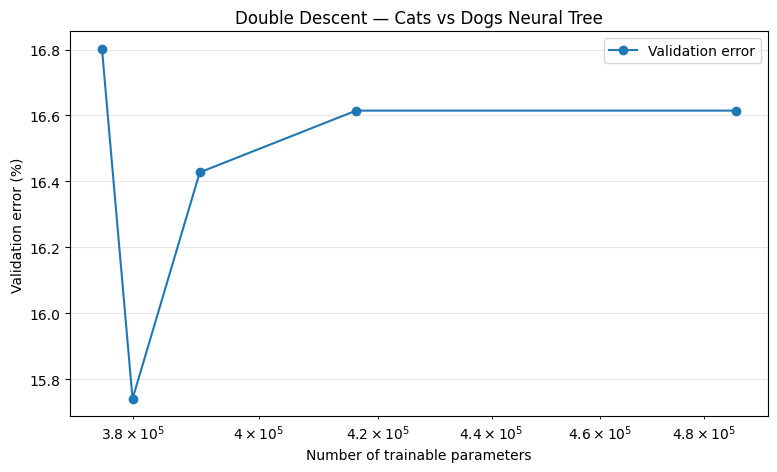

In [12]:

results_df = results_df.sort_values("parameters")

plt.figure(figsize=(9, 5))
plt.plot(
    results_df["parameters"],
    results_df["validation_error"],
    marker="o",
    label="Validation error"
)
plt.xlabel("Number of trainable parameters")
plt.ylabel("Validation error (%)")
plt.xscale("log")
plt.title("Double Descent — Cats vs Dogs Neural Tree")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [15]:
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
print(f"Trainable parameters: {total_params:,}")

Trainable parameters: 486,277


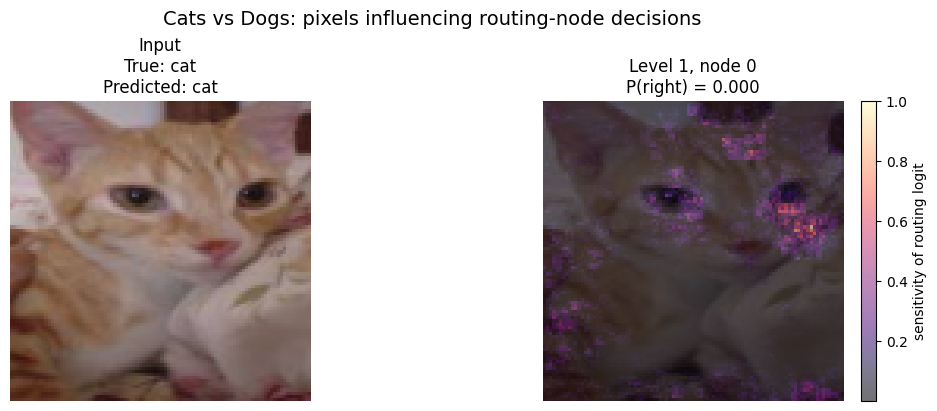

In [17]:
# Improved Cats vs Dogs routing saliency:
# compute gradients from the routing LOGIT, not the saturated sigmoid probability.

CLASS_NAMES = ("cat", "dog")
VIS_MEAN = torch.tensor([0.5, 0.5, 0.5]).view(3, 1, 1)
VIS_STD = torch.tensor([0.5, 0.5, 0.5]).view(3, 1, 1)

images, targets = next(iter(val_loader))
sample_index = 0
image = images[sample_index]
true_label = targets[sample_index].item()

def unnormalize(image_tensor):
    return (image_tensor.cpu() * VIS_STD + VIS_MEAN).clamp(0, 1)

display_image = unnormalize(image).permute(1, 2, 0)
node_indices = list(range(len(model.routers)))

model.eval()

with torch.no_grad():
    class_probabilities = model(image.unsqueeze(0).to(device))
    predicted_label = class_probabilities.argmax(dim=1).item()

fig, axes = plt.subplots(
    1,
    len(node_indices) + 1,
    figsize=(5 * (len(node_indices) + 1), 4),
    constrained_layout=True,
)

axes[0].imshow(display_image)
axes[0].set_title(
    f"Input\nTrue: {CLASS_NAMES[true_label]}\n"
    f"Predicted: {CLASS_NAMES[predicted_label]}"
)
axes[0].axis("off")

for ax, node_index in zip(axes[1:], node_indices):
    x = image.unsqueeze(0).to(device).detach().clone().requires_grad_(True)

    model.zero_grad(set_to_none=True)
    features = model.trunk(x)

    # Pre-sigmoid routing score: avoids vanishing gradients when P(right) is 0 or 1.
    routing_logit = model.routers[node_index].network(features)[0, 0]
    route_probability = torch.sigmoid(routing_logit).item()

    routing_logit.backward()

    saliency = x.grad.detach().abs().amax(dim=1)[0].cpu()
    saliency = saliency / (saliency.max() + 1e-8)

    ax.imshow(display_image)
    heatmap = ax.imshow(saliency, cmap="magma", alpha=0.55)

    level = int(torch.floor(torch.log2(torch.tensor(node_index + 1))).item()) + 1
    ax.set_title(
        f"Level {level}, node {node_index}\n"
        f"P(right) = {route_probability:.3f}"
    )
    ax.axis("off")

fig.colorbar(
    heatmap,
    ax=axes[1:].tolist(),
    fraction=0.045,
    pad=0.04,
    label="sensitivity of routing logit",
)

fig.suptitle(
    "Cats vs Dogs: pixels influencing routing-node decisions",
    fontsize=14,
)
plt.show()